# 04 · Aprender representaciones: autoencoders, VAEs, GANs y aprendizaje autosupervisado

Este es un módulo de Neural Networks 1002. Supone conocidos el [módulo 02 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/02-retropropagacion/) (retropropagación), el [módulo 03](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) (entrenar redes profundas) y el [módulo 05](https://neural-networks.academy.forwardforecasting.eu/es/05-redes-convolucionales/) (redes convolucionales, aquí solo por la idea de un codificador de imágenes).

Hasta ahora siempre le decíamos a la red la respuesta correcta. Aquí no. La pregunta es: **¿puede una red aprender algo útil solo con los datos, sin etiquetas?** Cuatro respuestas, en el orden en que las encontró el campo, y cada una prepara la siguiente:

1. **Autoencoders**: se comprimen los datos por un cuello de botella estrecho y se reconstruyen. Lo que sobrevive a la compresión es una representación aprendida, y lo que no se puede reconstruir es una anomalía.
2. **Autoencoders variacionales (VAE)**: se hace probabilístico el cuello de botella para que el espacio entre los códigos tenga sentido, y muestrear de él genera datos nuevos. El precio es el desenfoque.
3. **Redes generativas antagónicas (GAN)**: se sustituye la pérdida de reconstrucción por una segunda red que intenta distinguir lo real de lo falso. Muestras más nítidas, entrenamiento mucho más difícil.
4. **Aprendizaje autosupervisado**: se inventa una tarea cuya respuesta es gratuita (¿son estas dos vistas de la misma imagen?) y se aprenden representaciones mediante **aprendizaje contrastivo**. Termina en **CLIP** (contrastive language-image pre-training, preentrenamiento contrastivo lenguaje-imagen), que alinea imágenes y texto.

En este cuaderno construirás, en la CPU de un portátil y con semillas fijas:

* un autoencoder, y medirás la **detección de anomalías** por error de reconstrucción (área bajo la curva ROC, AUC) sobre una clase de dígitos que nunca vio, en función del tamaño del cuello de botella, con y sin eliminación de ruido;
* un VAE con la **ELBO** (evidence lower bound, cota inferior de la evidencia) y el **truco de reparametrización**, un mapa del espacio latente, interpolaciones y una medición del **compromiso del desenfoque** frente al peso del término KL;
* una GAN sobre una distribución 2D de juguete y sobre dígitos, con el **colapso de modos** mostrado y medido, la inestabilidad del juego de dos jugadores y las variantes hinge y de Wasserstein;
* un aprendiz contrastivo al estilo **SimCLR** con una pérdida **InfoNCE** y aumentos de datos escritos a mano, y una **curva de precisión de sonda lineal frente al número de etiquetas** que compara el entrenamiento supervisado desde cero, las características del autoencoder y las contrastivas;
* un pequeño **modelo contrastivo imagen-texto** (un CLIP en miniatura) entrenado con dígitos y sus descripciones, y después un **CLIP real preentrenado** ejecutado en la CPU para clasificación zero-shot.

**Contenido**

1. Preparación y datos
2. Autoencoders: cuello de botella, eliminación de ruido, detección de anomalías
3. Autoencoders variacionales: ELBO, reparametrización, desenfoque
4. Redes generativas antagónicas: un juego de dos jugadores
5. Aprendizaje autosupervisado: aprendizaje contrastivo con SimCLR
6. CLIP: alinear imágenes y texto
7. Hacia dónde lleva esto: difusión y modelos generalistas
8. Ideas clave, ejercicios, referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| [02 Red neuronal y retropropagación (1001)](https://neural-networks.academy.forwardforecasting.eu/es/02-retropropagacion/) | gradientes a través de una red, que PyTorch autograd calcula por nosotros (incluido un gradiente de un gradiente en la GAN de Wasserstein) |
| [03 Entrenar redes profundas (1001)](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) | Adam, tasas de aprendizaje, por qué los gradientes ruidosos u opuestos vuelven frágil el entrenamiento |
| [05 Redes convolucionales (1001)](https://neural-networks.academy.forwardforecasting.eu/es/05-redes-convolucionales/) | un codificador convierte una imagen en un vector; aquí los codificadores son redes densas pequeñas para ir rápido |

¿Nuevo en PyTorch? El [curso Python 1001, sección de frameworks de IA](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/) lo introduce. Los datos son los dígitos manuscritos de 8x8 que trae scikit-learn, así que no se descarga nada salvo el CLIP preentrenado de la sección 6 (unos 600 MB, una sola vez). **En qué se diferencian los juguetes de los sistemas reales:** los autoencoders, GANs y modelos contrastivos reales entrenan redes convolucionales o Transformers con millones de imágenes en color durante días en GPUs; nuestros dígitos de 64 píxeles y unos pocos miles de pasos muestran los mecanismos, no la escala, y algunos números (por ejemplo cuánto ayuda el aprendizaje contrastivo) dependen de que los datos sean diminutos.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/04_autoencoders_gans_y_autosupervisado.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 1 a 2 minutos, con un pico de memoria de unos 1,5 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'PIL': 'pillow',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'skimage': 'scikit-image',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'transformers': 'transformers',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

## 1. Preparación y datos

Los datos son el conjunto de **reconocimiento óptico de dígitos manuscritos** (Alpaydin y Kaynak, UCI Machine Learning Repository, licencia CC BY 4.0), 1.797 imágenes de 8x8 píxeles incluidas en scikit-learn, así que no se descarga nada. Los valores de píxel van de 0 (vacío) a 16 (tinta plena); los dividimos entre 16. Reservamos 1.200 imágenes para entrenar y 597 para probar. Las etiquetas solo se usan donde lo decimos.

Además entrenamos, una vez, una **regresión logística sobre los píxeles** como **juez**. No forma parte de ningún modelo. La usamos más adelante como regla: si el juez está seguro de una imagen generada, la imagen parece un dígito; si duda, la imagen es ambigua o está deformada. Alcanza cerca del 97 % de precisión en los dígitos reales de prueba, así que es una regla razonable para estos datos.

entrenamiento (1200, 64) prueba (597, 64) | precisión del juez en dígitos reales de prueba: 0.975


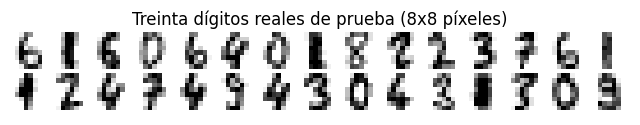

nitidez (variación total) de los dígitos reales: 0.237


In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

torch.set_num_threads(1)          # estas redes diminutas van más rápido con un solo hilo
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T0 = time.time()

digits = load_digits()
X = (digits.data / 16.0).astype(np.float32)          # (1797, 64), valores en [0, 1]
y = digits.target
rng = np.random.RandomState(0)
order = rng.permutation(len(X))
itr, ite = order[:1200], order[1200:]
Xtr, Xte, ytr, yte = X[itr], X[ite], y[itr], y[ite]

judge = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
print("entrenamiento", Xtr.shape, "prueba", Xte.shape, "| precisión del juez en dígitos reales de prueba:", round(judge.score(Xte, yte), 3))

def montage(imgs, ncols, side=8):
    # coloca imágenes planas (N, lado*lado) en una cuadrícula para imshow; la tinta se dibuja oscura
    imgs = np.asarray(imgs).reshape(-1, side, side)
    n = len(imgs); nrows = int(math.ceil(n / ncols))
    canvas = np.ones((nrows * (side + 1), ncols * (side + 1)))
    for k, im in enumerate(imgs):
        r, c = divmod(k, ncols)
        canvas[r * (side + 1): r * (side + 1) + side, c * (side + 1): c * (side + 1) + side] = 1 - im
    return canvas

def tv(imgs):
    # variación total: diferencia absoluta media entre píxeles vecinos (alta = nítida, baja = borrosa)
    a = np.asarray(imgs).reshape(-1, 8, 8)
    return float((np.abs(np.diff(a, axis=1)).mean() + np.abs(np.diff(a, axis=2)).mean()) / 2)

def make_mlp(sizes, out_act=None):
    layers = []
    for i in range(len(sizes) - 1):
        layers.append(nn.Linear(sizes[i], sizes[i + 1]))
        if i < len(sizes) - 2:
            layers.append(nn.ReLU())
    if out_act is not None:
        layers.append(out_act)
    return nn.Sequential(*layers)

TV_REAL = tv(Xte)
fig, ax = plt.subplots(figsize=(8, 2.2))
ax.imshow(montage(Xte[:30], 15), cmap="gray", vmin=0, vmax=1); ax.axis("off"); ax.grid(False)
ax.set_title("Treinta dígitos reales de prueba (8x8 píxeles)")
plt.show()
print("nitidez (variación total) de los dígitos reales:", round(TV_REAL, 3))

## 2. Autoencoders: cuello de botella, eliminación de ruido, detección de anomalías

Un **autoencoder** son dos redes pegadas. El **codificador** $f$ transforma una entrada $\mathbf{x}$ (64 píxeles) en un **código** corto $\mathbf{z} = f(\mathbf{x})$ de solo $d$ números, el **cuello de botella**. El **decodificador** $g$ lo devuelve a su forma, $\hat{\mathbf{x}} = g(\mathbf{z})$. El entrenamiento minimiza el **error de reconstrucción**, aquí el error cuadrático medio $\frac{1}{64}\lVert \mathbf{x} - \hat{\mathbf{x}} \rVert^2$. No hay etiquetas: la entrada es su propio objetivo.

Si $d$ fuera 64 o más, copiar la entrada sería una solución perfecta y no se aprendería nada. El cuello de botella estrecho obliga a la red a conservar solo lo común a muchos dígitos (trazos, bucles) y a descartar el resto. Hinton y Salakhutdinov (2006) mostraron que los autoencoders profundos dan códigos de baja dimensión mucho mejores que los métodos lineales como el PCA (análisis de componentes principales, que de hecho es el mejor autoencoder *lineal*).

Dos ideas hacen útiles a los autoencoders:

* **Eliminación de ruido** (Vincent et al., 2008). Se corrompe la entrada con ruido, $\tilde{\mathbf{x}} = \mathbf{x} + \sigma\boldsymbol{\epsilon}$ (donde $\sigma$ es el nivel de ruido y $\boldsymbol{\epsilon}$ ruido gaussiano estándar), pero se pide como salida el $\mathbf{x}$ limpio. La red no puede copiar, porque la entrada no es el objetivo, así que incluso un cuello ancho debe aprender la estructura de los dígitos. Esta idea reaparece en el módulo 05 de Neural Networks 1002 (los modelos de difusión son eliminadores de ruido).
* **Detección de anomalías por error de reconstrucción.** Se entrena el autoencoder solo con datos "normales". Con una entrada normal reconstruye bien; con algo que nunca vio reconstruye mal, porque su cuello de botella se ajustó a los datos normales. El error de reconstrucción es entonces una **puntuación de anomalía**. Así detectan los autoencoders piezas defectuosas, fraudes o historiales clínicos inusuales sin ningún ejemplo de fallo.

**El experimento.** Elegimos una clase de dígito como "anomalía" y entrenamos solo con las otras nueve (la red nunca la ha visto). En el conjunto de prueba, que contiene dígitos normales y la clase retenida, calculamos el error de reconstrucción de cada imagen y medimos lo bien que separa los dos grupos con el **AUC** (área bajo la curva ROC): 1,0 es perfecto, 0,5 es lanzar una moneda. Lo hacemos para dos clases retenidas (5 y 9, fáciles de confundir con otros dígitos) y tamaños de cuello $d \in \{2, 4, 8, 16, 32\}$, y para autoencoders con eliminación de ruido en $d = 8$ y $d = 32$.

AUC del error de reconstrucción como puntuación de anomalía (media sobre las clases retenidas 5 y 9)
cuello d | AE simple | AE con eliminación de ruido (sigma 0.3)
           2 |    0.747 |      nan
           4 |    0.864 |      nan
           8 |    0.944 |    0.922
          16 |    0.928 |      nan
          32 |    0.907 |    0.922
por clase, d=8 simple: {5: 0.981, 9: 0.907} | transcurrido 30 s
AE d=32 entrenado con ruido 0.0: error frente a la imagen limpia cuando la entrada tiene ruido 0.3 = 0.0334
AE d=32 entrenado con ruido 0.3: error frente a la imagen limpia cuando la entrada tiene ruido 0.3 = 0.0266


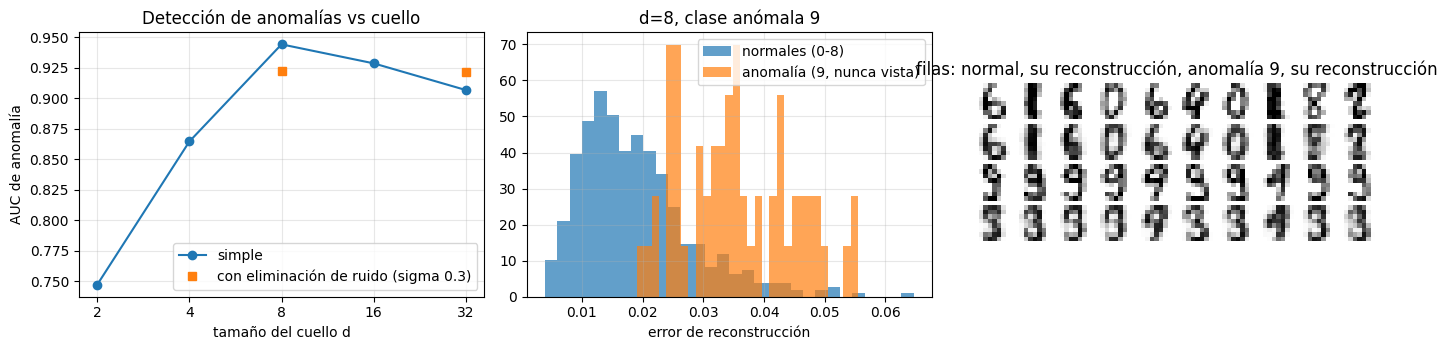

In [2]:
def train_ae(Xnp, dim, noise=0.0, epochs=40, seed=0, bs=128):
    # codificador 64-64-d, decodificador d-64-64 con salida sigmoide; error cuadrático medio contra la entrada LIMPIA
    torch.manual_seed(seed)
    enc = make_mlp([64, 64, dim]); dec = make_mlp([dim, 64, 64], nn.Sigmoid())
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), 3e-3)
    Xt = torch.tensor(Xnp)
    for ep in range(epochs):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), bs):
            xb = Xt[perm[i:i + bs]]
            xin = (xb + noise * torch.randn_like(xb)).clamp(0, 1) if noise > 0 else xb
            loss = F.mse_loss(dec(enc(xin)), xb)
            opt.zero_grad(); loss.backward(); opt.step()
    return enc, dec

def recon_err(model, Xnp, noise=0.0):
    enc, dec = model
    with torch.no_grad():
        xt = torch.tensor(Xnp)
        xin = (xt + noise * torch.randn_like(xt)).clamp(0, 1) if noise > 0 else xt
        return ((dec(enc(xin)) - xt) ** 2).mean(1).numpy()

HOLD = [5, 9]
DIMS = [2, 4, 8, 16, 32]
results = {}                # (clase retenida, dim, ruido) -> AUC
models = {}
for hold in HOLD:
    normal = itr[ytr != hold]
    for dim, noise in [(d, 0.0) for d in DIMS] + [(8, 0.3), (32, 0.3)]:
        m = train_ae(X[normal], dim, noise)
        err = recon_err(m, Xte)
        results[(hold, dim, noise)] = roc_auc_score(yte == hold, err)
        models[(hold, dim, noise)] = m

print("AUC del error de reconstrucción como puntuación de anomalía (media sobre las clases retenidas 5 y 9)")
print("cuello d | AE simple | AE con eliminación de ruido (sigma 0.3)")
for dim in DIMS:
    plain = np.mean([results[(h, dim, 0.0)] for h in HOLD])
    den = np.mean([results[(h, dim, 0.3)] for h in HOLD]) if dim in (8, 32) else float("nan")
    print(f"{dim:>12} | {plain:8.3f} | {den:8.3f}")
print("por clase, d=8 simple:", {h: round(results[(h, 8, 0.0)], 3) for h in HOLD}, "| transcurrido", round(time.time() - T0), "s")

# la eliminación de ruido en sí: error frente a la imagen limpia cuando la entrada es ruidosa (sigma 0.3), modelos entrenados sin la clase 9
torch.manual_seed(1)
for noise in (0.0, 0.3):
    e = recon_err(models[(9, 32, noise)], Xte, noise=0.3)[yte != 9].mean()
    print(f"AE d=32 entrenado con ruido {noise}: error frente a la imagen limpia cuando la entrada tiene ruido 0.3 = {e:.4f}")

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for noise, lab, st in [(0.0, "simple", "o-"), (0.3, "con eliminación de ruido (sigma 0.3)", "s")]:
    ds = DIMS if noise == 0 else [8, 32]
    axs[0].plot(ds, [np.mean([results[(h, d, noise)] for h in HOLD]) for d in ds], st, label=lab)
axs[0].set_xscale("log", base=2); axs[0].set_xticks(DIMS); axs[0].set_xticklabels(DIMS)
axs[0].set_xlabel("tamaño del cuello d"); axs[0].set_ylabel("AUC de anomalía"); axs[0].set_title("Detección de anomalías vs cuello"); axs[0].legend()
err = recon_err(models[(9, 8, 0.0)], Xte)
axs[1].hist(err[yte != 9], bins=30, alpha=0.7, label="normales (0-8)", density=True)
axs[1].hist(err[yte == 9], bins=30, alpha=0.7, label="anomalía (9, nunca vista)", density=True)
axs[1].set_xlabel("error de reconstrucción"); axs[1].set_title("d=8, clase anómala 9"); axs[1].legend()
enc, dec = models[(9, 8, 0.0)]
nrm = Xte[yte != 9][:10]; ano = Xte[yte == 9][:10]
with torch.no_grad():
    rows = [nrm, dec(enc(torch.tensor(nrm))).numpy(), ano, dec(enc(torch.tensor(ano))).numpy()]
axs[2].imshow(montage(np.concatenate(rows), 10), cmap="gray", vmin=0, vmax=1); axs[2].axis("off"); axs[2].grid(False)
axs[2].set_title("filas: normal, su reconstrucción, anomalía 9, su reconstrucción")
plt.tight_layout(); plt.show()

**Lectura.** Mira primero la tabla. Un cuello muy pequeño ($d = 2$) no puede ni reconstruir los dígitos normales, así que su error es alto para todo y las anomalías no destacan. El AUC sube al crecer el cuello, alcanza su máximo en $d = 8$ (0,94) y después baja (0,93 con 16, 0,91 con 32): con un cuello ancho la red empieza a copiar y reconstruye también la clase no vista, que es justo el fallo que el cuello de botella debía evitar. El mejor $d$ es un compromiso y depende de los datos, por eso se ajusta con datos de validación que contengan algunas anomalías, cuando existen. El autoencoder con eliminación de ruido es la variante útil cuando el cuello es ancho: como no puede copiar su entrada, conserva un AUC alto en $d = 32$ donde el simple tiende a perderlo (0,922 frente a 0,907 en nuestra ejecución, mientras que en $d = 8$ el simple es mejor, 0,944 frente a 0,922; y con entradas ruidosas el modelo con eliminación de ruido reconstruye la imagen limpia con un error un 20 % menor, 0,027 frente a 0,033). Salvedades honestas: dos clases retenidas y una semilla por configuración es un experimento pequeño, así que diferencias de unas centésimas de AUC están dentro del ruido; las reconstrucciones de la figura muestran el mecanismo (el 9 reconstruido se acerca a un dígito de aspecto normal), no una clasificación precisa. Además un 9 se parece genuinamente a un 4 o un 7, así que no cabe esperar un AUC de 1,0 con estos píxeles de 8x8.

## 3. Autoencoders variacionales: ELBO, reparametrización, desenfoque

Un autoencoder simple coloca cada imagen de entrenamiento en algún punto del espacio de códigos, pero nada dice qué hay **entre** los puntos. Si decodificas un código al azar, a menudo obtienes basura. Un **autoencoder variacional** (Kingma y Welling, 2014) lo arregla haciendo que el código sea una **distribución**.

El codificador ya no devuelve un código sino los parámetros de una gaussiana: una media $\boldsymbol{\mu}(\mathbf{x})$ y un logaritmo de la varianza $\log\boldsymbol{\sigma}^2(\mathbf{x})$ (ambos vectores con una entrada por dimensión latente; $\boldsymbol{\sigma}$ es el vector de desviaciones típicas). Se **muestrea** un código, $\mathbf{z} \sim \mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\sigma}^2)$, y el decodificador debe reconstruir $\mathbf{x}$ a partir de él. El entrenamiento maximiza la **ELBO** (evidence lower bound, cota inferior de la evidencia), una cota inferior del logaritmo de la probabilidad $\log p(\mathbf{x})$ que el modelo asigna a los datos:

$$\text{ELBO}(\mathbf{x}) = \underbrace{\mathbb{E}_{q(\mathbf{z}\mid\mathbf{x})}\big[\log p(\mathbf{x}\mid\mathbf{z})\big]}_{\text{reconstrucción}} \;-\; \underbrace{D_{\mathrm{KL}}\big(q(\mathbf{z}\mid\mathbf{x}) \,\Vert\, p(\mathbf{z})\big)}_{\text{término KL}}$$

Aquí $q(\mathbf{z}\mid\mathbf{x})$ es la gaussiana del codificador, $p(\mathbf{x}\mid\mathbf{z})$ es el decodificador y $p(\mathbf{z}) = \mathcal{N}(\mathbf{0}, \mathbf{I})$ es la **a priori** que queremos que sigan los códigos. $D_{\mathrm{KL}}$ es la **divergencia de Kullback-Leibler**, una medida de cuánto se aleja una distribución de otra (cero solo cuando son iguales). Para dos gaussianas tiene forma cerrada, que es la que usa el código:

$$D_{\mathrm{KL}} = -\tfrac{1}{2}\sum_{j}\big(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\big)$$

donde $j$ recorre las dimensiones latentes. Los dos términos tiran en direcciones opuestas. El de reconstrucción quiere códigos precisos ($\sigma$ pequeña, $\mu$ distinta para cada imagen). El KL quiere que cada distribución de código se parezca a la a priori, lo que comprime todas las imágenes en manchas superpuestas alrededor del origen. Esa superposición es justo lo que da sentido al espacio entre los códigos: un punto entre dos imágenes cae en una región que el decodificador ha visto.

**El truco de reparametrización.** Muestrear $\mathbf{z}$ es una operación aleatoria y los gradientes no pueden atravesar un sorteo. El truco es sacar el azar aparte, $\boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$, y calcular $\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma}\odot\boldsymbol{\epsilon}$ ($\odot$ es el producto elemento a elemento). Ahora $\mathbf{z}$ es una función derivable de $\boldsymbol{\mu}$ y $\boldsymbol{\sigma}$ y la retropropagación habitual funciona.

**El compromiso del desenfoque.** Tratamos cada píxel como una probabilidad de Bernoulli, así que el término de reconstrucción es la entropía cruzada binaria sumada sobre los 64 píxeles. Añadimos un peso $\beta$ delante del término KL (el "$\beta$-VAE" de Higgins et al., 2017; $\beta = 1$ es la ELBO verdadera). Un $\beta$ pequeño da reconstrucciones nítidas pero un espacio latente irregular; un $\beta$ grande da un espacio latente ordenado pero reconstrucciones que promedian todo lo que el código no distingue, lo que se ve **borroso**. Medimos cuatro cosas para $\beta \in \{0{,}1;\ 1;\ 4\}$ con espacio latente 2D (para poder dibujarlo) y para $\beta = 1$ con 8 dimensiones latentes: el error de reconstrucción en prueba, el coste KL por imagen en nats, la nitidez (variación total, como fracción de la de los dígitos reales) y lo parecidas a un dígito que le resultan al juez las muestras sacadas de la a priori. También decodificamos rectas entre pares de imágenes de dígitos distintos, para el VAE y para un autoencoder simple 2D, y medimos con qué frecuencia el juez está seguro de las imágenes del medio de la recta.

config (dim latente, beta) | MSE prueba | KL nats | nitidez vs real | conf. del juez en muestras a priori | conf. a mitad de interpolación
                 (2, 0.1) | 0.0397   |    5.8  |  0.80             | 0.661                        | 0.611


                 (2, 1.0) | 0.0399   |    2.4  |  0.76             | 0.629                        | 0.570
                 (2, 4.0) | 0.0744   |    0.0  |  0.53             | 0.301                        | 0.297


                 (8, 1.0) | 0.0259   |    3.3  |  0.80             | 0.674                        | 0.638
            plain AE, d=2 | 0.0426   |    n/a  |  0.78             | (no prior)                   | 0.531
transcurrido 56 s


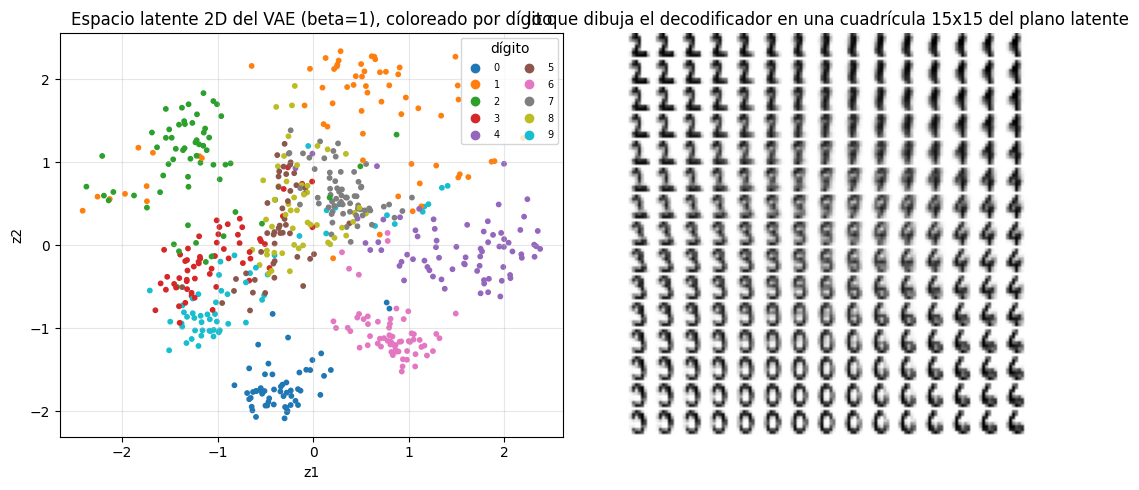

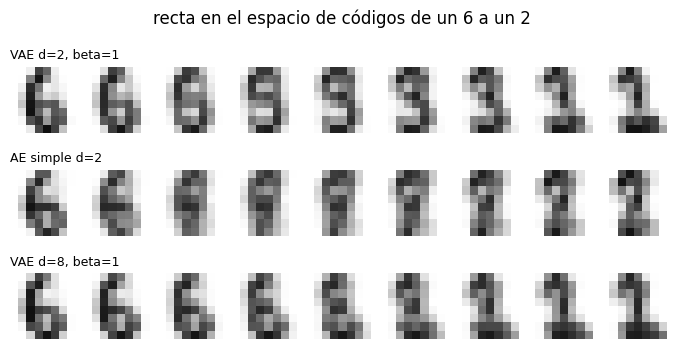

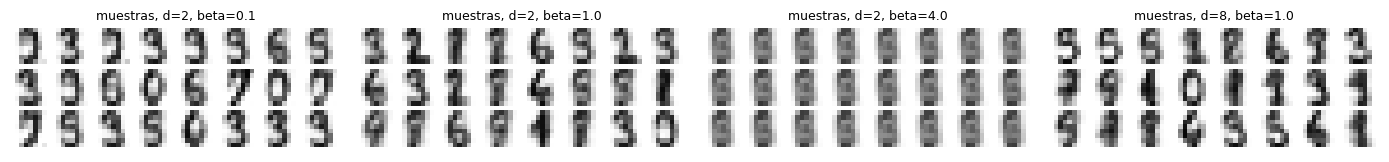

In [3]:
class VAE(nn.Module):
    def __init__(self, zdim, h=128):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(64, h), nn.ReLU())
        self.mu = nn.Linear(h, zdim); self.logvar = nn.Linear(h, zdim)
        self.dec = make_mlp([zdim, h, 64])               # devuelve logits, la sigmoide está dentro de la pérdida
    def encode(self, x):
        h = self.body(x); return self.mu(h), self.logvar(h)
    def forward(self, x):
        mu, logvar = self.encode(x)
        eps = torch.randn_like(mu)
        z = mu + torch.exp(0.5 * logvar) * eps           # truco de reparametrización
        return self.dec(z), mu, logvar

def vae_loss(logits, x, mu, logvar, beta):
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(1)   # -log p(x|z), sumado sobre los píxeles
    kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(1)                       # KL gaussiana en forma cerrada
    return (rec + beta * kl).mean(), rec.mean(), kl.mean()

def train_vae(zdim, beta, epochs=80, seed=0, bs=128):
    torch.manual_seed(seed)
    m = VAE(zdim); opt = torch.optim.Adam(m.parameters(), 3e-3)
    Xt = torch.tensor(Xtr)
    for ep in range(epochs):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), bs):
            xb = Xt[perm[i:i + bs]]
            logits, mu, lv = m(xb)
            loss, _, _ = vae_loss(logits, xb, mu, lv, beta)
            opt.zero_grad(); loss.backward(); opt.step()
    return m

CONFIGS = [(2, 0.1), (2, 1.0), (2, 4.0), (8, 1.0)]
vaes = {c: train_vae(*c) for c in CONFIGS}
ae2 = train_ae(Xtr, 2, epochs=40)                        # autoencoder simple 2D para la comparación de interpolaciones

def mid_confidence(decode_path, pairs):
    # probabilidad máxima media del juez en el medio de la recta entre dos imágenes de clases distintas
    confs = []
    for a, b in pairs:
        imgs = decode_path(a, b)
        confs.append(judge.predict_proba(imgs[2:-2]).max(1).mean())
    return float(np.mean(confs))

rs = np.random.RandomState(1)
pairs = []
while len(pairs) < 60:
    a, b = rs.choice(len(Xte), 2, replace=False)
    if yte[a] != yte[b]:
        pairs.append((a, b))
ts = np.linspace(0, 1, 9)

def vae_path(m):
    def f(a, b):
        with torch.no_grad():
            za = m.encode(torch.tensor(Xte[[a]]))[0]; zb = m.encode(torch.tensor(Xte[[b]]))[0]
            return torch.sigmoid(m.dec(torch.stack([(1 - t) * za[0] + t * zb[0] for t in ts]))).numpy()
    return f
def ae_path(m):
    def f(a, b):
        enc, dec = m
        with torch.no_grad():
            za = enc(torch.tensor(Xte[[a]])); zb = enc(torch.tensor(Xte[[b]]))
            return dec(torch.stack([(1 - t) * za[0] + t * zb[0] for t in ts])).numpy()
    return f

print("config (dim latente, beta) | MSE prueba | KL nats | nitidez vs real | conf. del juez en muestras a priori | conf. a mitad de interpolación")
torch.manual_seed(5)
for c, m in vaes.items():
    with torch.no_grad():
        xt = torch.tensor(Xte)
        mu, lv = m.encode(xt)
        rec = torch.sigmoid(m.dec(mu)).numpy()
        kl = (-0.5 * (1 + lv - mu ** 2 - lv.exp()).sum(1)).mean().item()
        samp = torch.sigmoid(m.dec(torch.randn(500, c[0]))).numpy()
    print(f"{str(c):>25} | {((rec - Xte) ** 2).mean():.4f}   | {kl:6.1f}  | {tv(rec) / TV_REAL:5.2f}             | {judge.predict_proba(samp).max(1).mean():.3f}                        | {mid_confidence(vae_path(m), pairs):.3f}")
with torch.no_grad():
    rec = ae2[1](ae2[0](torch.tensor(Xte))).numpy()
print(f"{'plain AE, d=2':>25} | {((rec - Xte) ** 2).mean():.4f}   |    n/a  | {tv(rec) / TV_REAL:5.2f}             | (no prior)                   | {mid_confidence(ae_path(ae2), pairs):.3f}")
print("transcurrido", round(time.time() - T0), "s")

# figuras: mapa latente del VAE 2D con beta=1, cuadrícula decodificada sobre el plano, tiras de interpolación, muestras a priori
m = vaes[(2, 1.0)]
with torch.no_grad():
    mu_all = m.encode(torch.tensor(Xte))[0].numpy()
    lim = 2.6; g = np.linspace(-lim, lim, 15)
    grid_imgs = torch.sigmoid(m.dec(torch.tensor([[a, b] for b in g[::-1] for a in g], dtype=torch.float32))).numpy()
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
sc = axs[0].scatter(mu_all[:, 0], mu_all[:, 1], c=yte, cmap="tab10", s=10)
axs[0].set_title("Espacio latente 2D del VAE (beta=1), coloreado por dígito"); axs[0].set_xlabel("z1"); axs[0].set_ylabel("z2")
axs[0].legend(*sc.legend_elements(), ncol=2, fontsize=7, title="dígito", loc="upper right")
axs[1].imshow(montage(grid_imgs, 15), cmap="gray", vmin=0, vmax=1); axs[1].axis("off"); axs[1].grid(False)
axs[1].set_title("lo que dibuja el decodificador en una cuadrícula 15x15 del plano latente")
plt.tight_layout(); plt.show()

a, b = pairs[3]
strips = [vae_path(vaes[(2, 1.0)])(a, b), ae_path(ae2)(a, b), vae_path(vaes[(8, 1.0)])(a, b)]
fig, axs = plt.subplots(3, 1, figsize=(9, 3.6))
for ax, s, t in zip(axs, strips, ["VAE d=2, beta=1", "AE simple d=2", "VAE d=8, beta=1"]):
    ax.imshow(montage(s, 9), cmap="gray", vmin=0, vmax=1); ax.axis("off"); ax.grid(False); ax.set_title(t, fontsize=9, loc="left")
fig.suptitle(f"recta en el espacio de códigos de un {yte[a]} a un {yte[b]}"); plt.tight_layout(); plt.show()

torch.manual_seed(2)
fig, axs = plt.subplots(1, 4, figsize=(14, 2.6))
for ax, c in zip(axs, CONFIGS):
    with torch.no_grad():
        s = torch.sigmoid(vaes[c].dec(torch.randn(24, c[0]))).numpy()
    ax.imshow(montage(s, 8), cmap="gray", vmin=0, vmax=1); ax.axis("off"); ax.grid(False); ax.set_title(f"muestras, d={c[0]}, beta={c[1]}", fontsize=9)
plt.tight_layout(); plt.show()

**Lectura.** La tabla cuenta el compromiso, y una fila es una sorpresa. Pasar de $\beta = 0{,}1$ a $\beta = 1$ cuesta poco (error de prueba 0,0397 a 0,0399, nitidez 0,80 a 0,76 de la de los dígitos reales) y el coste KL por imagen baja de 5,8 a 2,4 nats. Con $\beta = 4$ el modelo sufre **colapso posterior**: el término KL es 0,0, todos los códigos son iguales a la a priori, el decodificador ignora el código y devuelve siempre el mismo dígito promedio borroso (error 0,074, nitidez 0,53, el juez duda de todo). Es el compromiso del desenfoque en su extremo: cuando el código se abarata tanto que no puede informar, la mejor respuesta píxel a píxel es la media. El mapa 2D muestra por qué un VAE es un generador: códigos vecinos se decodifican como dígitos parecidos y la cuadrícula dibujada por el decodificador pasa suavemente de un dígito a otro. En la prueba de la recta, el juez está más seguro en el medio de los caminos del VAE (0,57 a 0,64) que en los del autoencoder simple 2D (0,53), una diferencia modesta con una semilla y 60 pares. El VAE de 8 dimensiones latentes reconstruye mejor (error 0,026) y sus muestras de la a priori son las más reconocibles (confianza del juez 0,67, frente a 0,90 en dígitos reales), pero las diferencias de calidad de muestras entre $\beta = 0{,}1$ y $\beta = 1$ están dentro de lo esperable por ruido de semilla. El desenfoque no es un error: con una verosimilitud píxel a píxel, la mejor respuesta a "qué hay en este píxel" bajo incertidumbre es el promedio, y el promedio de dos trazos es una mancha. Las GANs, a continuación, sustituyen la verosimilitud por píxel y lo pagan en otra parte.

## 4. Redes generativas antagónicas: un juego de dos jugadores

Un VAE juzga su salida con una fórmula fija (error por píxel). Una **GAN** (Goodfellow et al., 2014) deja que una segunda red aprenda a juzgar. Dos jugadores:

* el **generador** $G$ convierte ruido aleatorio $\mathbf{z}$ en una muestra falsa $G(\mathbf{z})$;
* el **discriminador** $D$ mira una muestra y devuelve la probabilidad de que sea real.

El objetivo original es un **juego minimax** sobre una función de valor $V$:

$$\min_G \max_D \; V(D, G) = \mathbb{E}_{\mathbf{x} \sim p_{\text{data}}}\big[\log D(\mathbf{x})\big] + \mathbb{E}_{\mathbf{z} \sim p_{\mathbf{z}}}\big[\log\big(1 - D(G(\mathbf{z}))\big)\big]$$

donde $p_{\text{data}}$ es la distribución de los datos y $p_{\mathbf{z}}$ la del ruido. $D$ se entrena para distinguir lo real de lo falso; $G$ para engañar a $D$. En el equilibrio ideal $G$ reproduce exactamente la distribución de los datos y $D$ devuelve $\tfrac12$ en todas partes. En la práctica $G$ se entrena con la pérdida **no saturante** $-\log D(G(\mathbf{z}))$, que da gradientes útiles cuando $D$ va ganando, y las dos redes dan pasos de Adam alternados.

No hay una pérdida que minimizar, solo un juego, y de ahí vienen los problemas:

* **Inestabilidad.** La mejor jugada de cada jugador depende del otro. Actualizar ambos con descenso de gradiente puede dar vueltas eternamente en vez de converger, las curvas de pérdida no miden la calidad, y un discriminador demasiado bueno deja al generador sin gradiente útil.
* **Colapso de modos.** Se premia al generador por engañar a $D$ *ahora mismo*. Si encuentra una salida que engaña a $D$, producir solo esa es una buena estrategia local. El generador cubre entonces unos pocos **modos** (grupos) de los datos e ignora el resto; el discriminador aprende a rechazar esa salida, el generador salta a otra, y así sucesivamente.

**Juguete 1: ocho gaussianas en un anillo.** El objetivo son ocho grupos pequeños ($\sigma = 0{,}1$) sobre una circunferencia de radio 2. Lo vemos todo y podemos medir con exactitud. Con 2.000 puntos generados calculamos los **modos cubiertos** (grupos que reciben al menos el 1 % de los puntos, de 8) y la **tasa de acierto** (fracción de puntos a menos de tres $\sigma$ del centro de algún grupo, una medida de calidad). Comparamos tres configuraciones: una GAN **equilibrada** (ambas redes con tasa de aprendizaje $10^{-3}$); la misma GAN con una pareja de tasas **desequilibrada** (generador $5\times10^{-3}$, discriminador $5\times10^{-4}$); y la misma pareja desequilibrada con la variante de **pérdida hinge**: $D$ minimiza $\max(0, 1 - D(\mathbf{x})) + \max(0, 1 + D(G(\mathbf{z})))$ y $G$ minimiza $-D(G(\mathbf{z}))$ (Lim y Ye, 2017), una pérdida de margen sobre puntuaciones crudas sin sigmoide saturante.

configuración            | modos cubiertos por semilla (de 8) | acierto por semilla | modos medios


balanced GAN             | [8, 8, 8] | [0.8, 0.78, 0.81] | 8.0


unbalanced GAN           | [1, 1, 1] | [0.7, 0.15, 0.1] | 1.0


unbalanced, hinge loss   | [1, 2, 1] | [0.83, 0.12, 0.12] | 1.3
transcurrido 166 s


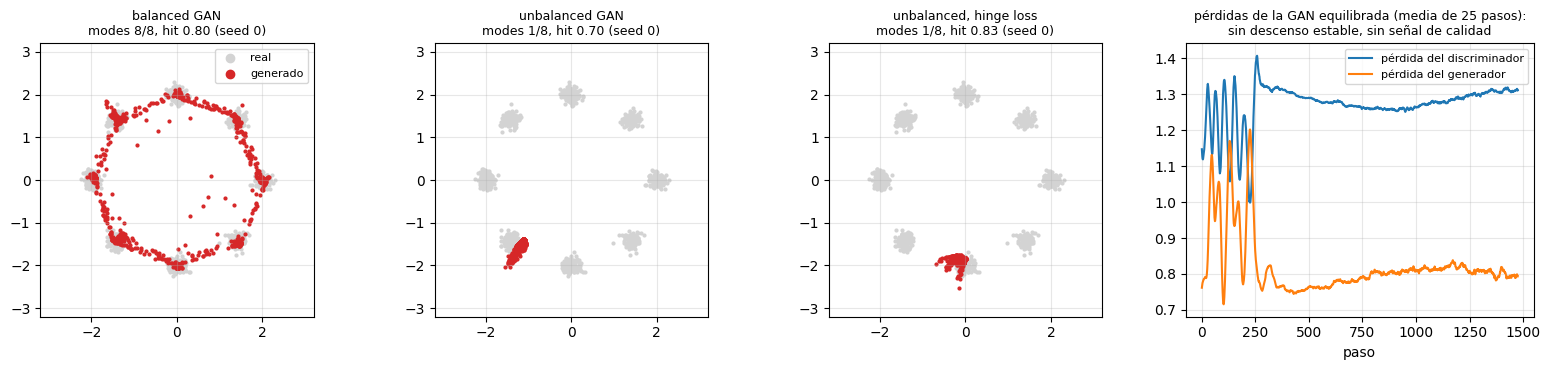

In [4]:
ANG = np.arange(8) * 2 * np.pi / 8
MODES = np.stack([2 * np.cos(ANG), 2 * np.sin(ANG)], 1).astype(np.float32)
SIG = 0.1

def real_toy(n, g):
    k = torch.randint(0, 8, (n,), generator=g)
    return torch.tensor(MODES)[k] + SIG * torch.randn(n, 2, generator=g)

def coverage(x):
    d = torch.cdist(x, torch.tensor(MODES)); near = d.min(1)
    hit = near.values < 3 * SIG
    cnt = torch.bincount(near.indices[hit], minlength=8)
    return int((cnt >= 0.01 * len(x)).sum()), float(hit.float().mean())

def train_toy(kind, seed, steps, lrg=1e-3, lrd=1e-3, ncritic=1, track=False):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    G = make_mlp([2, 64, 64, 2]); D = make_mlp([2, 64, 64, 1])
    betas = (0.5, 0.999) if kind in ("gan", "hinge") else (0.0, 0.9)
    oG = torch.optim.Adam(G.parameters(), lrg, betas=betas); oD = torch.optim.Adam(D.parameters(), lrd, betas=betas)
    bce = nn.BCEWithLogitsLoss(); B = 128
    hist = []
    for s in range(steps):
        for _ in range(ncritic):
            xr = real_toy(B, g); xf = G(torch.randn(B, 2)).detach()
            if kind == "gan":
                ld = bce(D(xr), torch.ones(B, 1)) + bce(D(xf), torch.zeros(B, 1))
            elif kind == "hinge":
                ld = F.relu(1 - D(xr)).mean() + F.relu(1 + D(xf)).mean()
            else:       # crítico de Wasserstein con penalización del gradiente (Gulrajani et al., 2017)
                a = torch.rand(B, 1); xi = (a * xr + (1 - a) * xf).requires_grad_(True)
                grad = torch.autograd.grad(D(xi).sum(), xi, create_graph=True)[0]
                ld = D(xf).mean() - D(xr).mean() + 10 * ((grad.norm(dim=1) - 1) ** 2).mean()
            oD.zero_grad(); ld.backward(); oD.step()
        out = D(G(torch.randn(B, 2)))
        lg = bce(out, torch.ones(B, 1)) if kind == "gan" else -out.mean()
        oG.zero_grad(); lg.backward(); oG.step()
        if track:
            hist.append((ld.item(), lg.item()))
    with torch.no_grad():
        return G, coverage(G(torch.randn(2000, 2))), np.array(hist)

SETTINGS = [("balanced GAN", "gan", dict(steps=1500)),
            ("unbalanced GAN", "gan", dict(steps=1000, lrg=5e-3, lrd=5e-4)),
            ("unbalanced, hinge loss", "hinge", dict(steps=1000, lrg=5e-3, lrd=5e-4))]
toy = {}
print("configuración            | modos cubiertos por semilla (de 8) | acierto por semilla | modos medios")
for name, kind, kw in SETTINGS:
    outs = [train_toy(kind, s, track=(s == 0), **kw) for s in range(3)]
    toy[name] = outs
    print(f"{name:24} | {[o[1][0] for o in outs]} | {[round(o[1][1], 2) for o in outs]} | {np.mean([o[1][0] for o in outs]):.1f}")
print("transcurrido", round(time.time() - T0), "s")

fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
rt = real_toy(1000, torch.Generator().manual_seed(9)).numpy()
for ax, (name, _, _) in zip(axs[:3], SETTINGS):
    G = toy[name][0][0]
    with torch.no_grad():
        p = G(torch.randn(1000, 2)).numpy()
    ax.scatter(rt[:, 0], rt[:, 1], s=4, c="lightgray", label="real"); ax.scatter(p[:, 0], p[:, 1], s=4, c="C3", label="generado")
    ax.set_title(f"{name}\nmodes {toy[name][0][1][0]}/8, hit {toy[name][0][1][1]:.2f} (seed 0)", fontsize=9); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2); ax.set_aspect("equal")
axs[0].legend(markerscale=3, fontsize=8)
h = toy["balanced GAN"][0][2]
k = 25; sm = lambda v: np.convolve(v, np.ones(k) / k, mode="valid")
axs[3].plot(sm(h[:, 0]), label="pérdida del discriminador"); axs[3].plot(sm(h[:, 1]), label="pérdida del generador")
axs[3].set_xlabel("paso"); axs[3].set_title("pérdidas de la GAN equilibrada (media de 25 pasos):\nsin descenso estable, sin señal de calidad", fontsize=9); axs[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.** En la configuración equilibrada la GAN simple encontró los ocho grupos en las tres semillas (tasa de acierto cerca de 0,8), algo que conviene decir claramente: el colapso de modos no está garantizado, aparece cuando el equilibrio entre los jugadores falla o el objetivo es más difícil. Con las tasas desequilibradas el generador se adelantó al discriminador y las tres semillas colapsaron a un solo modo (y en dos de ellas la tasa de acierto es solo 0,1 a 0,15: el punto colapsado queda entre grupos). La pérdida hinge con la misma configuración desequilibrada no lo rescató (1, 2 y 1 modos): otra pérdida no sustituye a un equilibrio sensato. Tres semillas son una indicación aproximada, no una prueba.

**La variante de Wasserstein.** Arjovsky et al. (2017) argumentaron que la pérdida original es una mala guía porque, cuando las distribuciones real y falsa apenas se solapan, la divergencia que implica es plana y el generador no recibe gradiente. Sustituyen el discriminador por un **crítico** que devuelve una puntuación sin acotar y aproxima la **distancia de Wasserstein** (el coste de mover la distribución generada hasta la real, la "distancia del movimiento de tierras"); el crítico debe ser **1-Lipschitz** (su salida no puede cambiar más deprisa que su entrada), lo que se impuso originalmente recortando los pesos y después, mucho mejor, con una **penalización del gradiente** que empuja la norma del gradiente del crítico hacia 1 (Gulrajani et al., 2017). La pérdida del crítico es $\mathbb{E}[D(G(\mathbf{z}))] - \mathbb{E}[D(\mathbf{x})] + \lambda\,\mathbb{E}[(\lVert\nabla D(\hat{\mathbf{x}})\rVert - 1)^2]$ con $\lambda = 10$ y $\hat{\mathbf{x}}$ un punto aleatorio de la recta entre una muestra real y una falsa. La pérdida del crítico correlaciona entonces con la calidad de las muestras, lo que la convierte en una curva de entrenamiento utilizable. El precio es un doble paso hacia atrás y varios pasos del crítico por cada paso del generador. La función `train_toy` de arriba ya lo contiene (`kind="wgan"`); la celda siguiente lo ejecuta una vez con un presupuesto corto.

In [5]:
t = time.time()
Gw, (modes_w, hit_w), _ = train_toy("wgan", 0, 1200, ncritic=2)
print(f"Crítico de Wasserstein con penalización del gradiente, 1200 pasos del generador, 2 del crítico cada uno, semilla 0: modos {modes_w}/8, tasa de acierto {hit_w:.2f}  ({time.time() - t:.0f} s)")

Crítico de Wasserstein con penalización del gradiente, 1200 pasos del generador, 2 del crítico cada uno, semilla 0: modos 1/8, tasa de acierto 0.04  (26 s)


**Lectura.** Esta ejecución falló: 1 modo de 8 y una tasa de acierto casi nula tras 1.200 pasos del generador. Lo contamos porque es el resultado honesto de un presupuesto corto, una semilla y ajustes sin afinar, no porque la pérdida de Wasserstein sea peor: los artículos originales entrenan decenas de miles de pasos con pasos del crítico y tasas de aprendizaje bien elegidos, y el crítico con penalización del gradiente tarda más en afilar el generador que la pérdida simple. Lo que sí muestra la celda es el coste: un doble paso hacia atrás y varios pasos del crítico por cada paso del generador. El ejercicio 6 te pide una ejecución más larga.

**Juguete 2: dígitos.** El mismo juego sobre los dígitos de 64 píxeles: un generador con 16 números de ruido de entrada y un discriminador, ambas redes densas pequeñas. No podemos contar modos a ojo, así que usamos el juez: la **cobertura de clases** es el número de clases de dígito (de 10) que reciben al menos el 2 % de las muestras según la predicción del juez, la **entropía de clases** (como fracción del máximo, $\ln 10$) dice lo uniformemente que se producen las clases, la **confianza del juez** dice lo parecidas a un dígito que son las muestras, y la **diversidad** es la distancia media entre pares aleatorios de imágenes generadas dividida por la misma cantidad en imágenes reales (un generador colapsado tiene una diversidad muy inferior a 1). Entrenamos la configuración equilibrada y otra con generador dominante (las mismas tasas desequilibradas de arriba).

configuración                    | clases de 10 | entropía de clases | conf. juez | diversidad
dígitos reales de prueba         |            10 |         1.00 | 0.903       | 1.00
balanced (2e-3 / 2e-3)           |            10 |         0.98 | 0.720       | 0.97
generator-heavy (1e-2 / 5e-4)    |             9 |         0.83 | 0.592       | 1.03
transcurrido 220 s


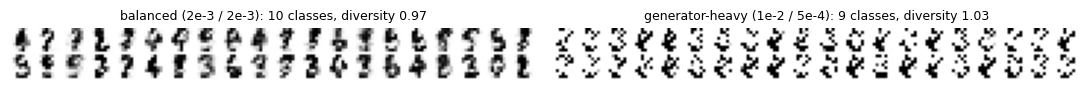

In [6]:
def train_digit_gan(seed, steps, lrg, lrd, B=64):
    torch.manual_seed(seed)
    G = make_mlp([16, 128, 64], nn.Sigmoid()); D = make_mlp([64, 128, 1])
    oG = torch.optim.Adam(G.parameters(), lrg, betas=(0.5, 0.999)); oD = torch.optim.Adam(D.parameters(), lrd, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss(); Xt = torch.tensor(Xtr)
    for s in range(steps):
        xr = Xt[torch.randint(0, len(Xt), (B,))]; xf = G(torch.randn(B, 16)).detach()
        ld = bce(D(xr), torch.ones(B, 1)) + bce(D(xf), torch.zeros(B, 1))
        oD.zero_grad(); ld.backward(); oD.step()
        lg = bce(D(G(torch.randn(B, 16))), torch.ones(B, 1))
        oG.zero_grad(); lg.backward(); oG.step()
    return G

def pair_dist(a):
    i = np.random.RandomState(0).permutation(len(a)); return float(np.linalg.norm(a[i[:250]] - a[i[250:500]], axis=1).mean())

def gan_report(G):
    with torch.no_grad():
        s = G(torch.randn(1000, 16)).numpy()
    pr = judge.predict_proba(s); share = np.bincount(pr.argmax(1), minlength=10) / len(s)
    ent = -(share[share > 0] * np.log(share[share > 0])).sum() / np.log(10)
    return s, dict(classes=int((share >= 0.02).sum()), entropy=ent, conf=pr.max(1).mean(), diversity=pair_dist(s) / pair_dist(Xte), share=share)

dg = {}
for name, lrg, lrd in [("balanced (2e-3 / 2e-3)", 2e-3, 2e-3), ("generator-heavy (1e-2 / 5e-4)", 1e-2, 5e-4)]:
    dg[name] = gan_report(train_digit_gan(0, 1500, lrg, lrd))
real_share = np.bincount(yte, minlength=10) / len(yte)
print(f"{'configuración':32} | clases de 10 | entropía de clases | conf. juez | diversidad")
print(f"{'dígitos reales de prueba':32} | {int((real_share >= 0.02).sum()):13d} | {-(real_share * np.log(real_share)).sum() / np.log(10):12.2f} | {judge.predict_proba(Xte).max(1).mean():.3f}       | 1.00")
for name, (s, r) in dg.items():
    print(f"{name:32} | {r['classes']:13d} | {r['entropy']:12.2f} | {r['conf']:.3f}       | {r['diversity']:.2f}")
print("transcurrido", round(time.time() - T0), "s")

fig, axs = plt.subplots(1, 2, figsize=(11, 3))
for ax, (name, (s, r)) in zip(axs, dg.items()):
    ax.imshow(montage(s[:40], 20), cmap="gray", vmin=0, vmax=1); ax.axis("off"); ax.grid(False)
    ax.set_title(f"{name}: {r['classes']} classes, diversity {r['diversity']:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

**Lectura.** La GAN equilibrada produce dígitos de las diez clases en proporciones casi iguales (entropía de clases 0,98) con una confianza del juez de 0,72, superior a la de las muestras del VAE (0,63 a 0,67) pero muy inferior a la de los dígitos reales (0,90): los dígitos generados son reconocibles pero a menudo ambiguos. La ejecución con generador dominante **no** es un colapso en dígitos: sigue produciendo nueve clases, la diversidad es 1,03, pero las proporciones son desiguales (entropía 0,83) y la confianza del juez baja a 0,59, así que las muestras se parecen menos a un dígito. No obtuvimos un colapso de modos limpio en dígitos en esta ejecución, y el anillo 2D de arriba es donde se mide el fallo. Una diversidad cercana a 1 también la alcanzan las imágenes ruidosas, por eso se lee junto con la confianza del juez. Una semilla y 1.500 pasos: tómalo como ilustración de las mediciones. Las GANs reales (DCGAN, StyleGAN y otras) resuelven estos problemas con arquitecturas convolucionales, normalización, equilibrado cuidadoso y muchos trucos; desde 2021 los modelos de difusión (módulo 05 de Neural Networks 1002) las han sustituido en casi toda la generación de imágenes precisamente porque su entrenamiento es una simple regresión sin nada de esta fragilidad.

## 5. Aprendizaje autosupervisado: aprendizaje contrastivo con SimCLR

Las etiquetas son caras: un radiólogo, un químico o un abogado tiene que producir cada una. Los datos sin etiquetar son casi gratis. El **aprendizaje autosupervisado** inventa una **tarea pretexto** cuya respuesta sale de los propios datos, entrena una red con ella y luego reutiliza la red como **extractor de características** para la tarea real, para la cual bastan pocas etiquetas. Los autoencoders fueron una tarea pretexto temprana (reconstruir la entrada). Otras: predecir una palabra enmascarada (BERT), predecir la palabra siguiente (módulo 10 de Neural Networks 1001), predecir la rotación de una imagen, rellenar un parche enmascarado. La familia más influyente para imágenes hasta hace poco es el **aprendizaje contrastivo**.

**La idea.** Se toma una imagen y se hacen dos **vistas aumentadas** aleatorias (desplazada, girada, reescalada, atenuada, ruidosa). Dos vistas de la misma imagen forman un **par positivo**; las vistas de imágenes distintas del lote son **negativos**. Se entrena un codificador para que las dos vistas de una imagen tengan representaciones cercanas y las de imágenes distintas representaciones lejanas. Para lograrlo, el codificador debe ignorar todo lo que cambian los aumentos (posición, brillo) y conservar lo que permanece (la identidad del dígito). **Los aumentos son la supervisión**: dicen qué no debe importar.

**SimCLR** (Chen et al., 2020) es la receta más simple. Se codifican ambas vistas con un codificador $f$ (cuya salida es la **representación** que conservaremos), se pasa por una pequeña **cabeza de proyección** $h$ (que se descarta tras el entrenamiento) y se normaliza en L2 el resultado en vectores $\mathbf{z}_i$. Para un lote de $N$ imágenes hay $2N$ vistas. La pérdida de una vista $i$ cuyo compañero positivo es $j(i)$ es la pérdida **InfoNCE** (van den Oord et al., 2018), también llamada NT-Xent (entropía cruzada normalizada con temperatura):

$$\ell_i = -\log \frac{\exp\big(\mathbf{z}_i\cdot\mathbf{z}_{j(i)} / \tau\big)}{\sum_{k \neq i} \exp\big(\mathbf{z}_i\cdot\mathbf{z}_k / \tau\big)}$$

La suma del denominador recorre las otras $2N - 1$ vistas, y $\tau$ es la **temperatura** (un número positivo pequeño, aquí 0,2) que afila la softmax. Es un problema de clasificación: entre $2N - 1$ candidatas, elegir a la verdadera pareja. Es una cota inferior de la información mutua entre las dos vistas, de ahí el nombre.

**Hacer que la tarea exija invarianza.** En los dígitos 8x8 simples, un clasificador lineal sobre píxeles crudos ya es excelente (97 %), así que una representación tiene poco que añadir y un experimento honesto mostraría un empate. Las imágenes reales no son así: el objeto está en cualquier parte del encuadre y a cualquier escala. Lo imitamos pegando cada dígito en una **posición aleatoria dentro de un lienzo de 12x12**, de modo que el mismo dígito aparece en 25 lugares distintos y los píxeles crudos dejan de ser linealmente separables. Los aumentos de SimCLR (giro aleatorio de hasta 12 grados, escala de 0,85 a 1,15, traslación de hasta unos 2 píxeles, brillo de 0,6 a 1,4, ruido gaussiano) se escriben abajo en pocas líneas con `affine_grid` y `grid_sample`, que aplican una transformación afín aleatoria distinta a cada imagen del lote a la vez.

**La medición: una curva de sonda lineal.** Para comparar representaciones con justicia las congelamos y entrenamos solo un **clasificador lineal** (una regresión logística) encima, con $n$ ejemplos etiquetados, con $n$ de 10 a los 1.200 completos. Esta **sonda lineal** prueba cuánta estructura de clases se puede leer ya linealmente. Comparamos, para cada $n$:

* **píxeles crudos** (sin aprendizaje de representaciones, la línea base);
* **supervisado desde cero**: la misma arquitectura de codificador seguida de una capa lineal, entrenada de extremo a extremo solo con las $n$ etiquetas (sin datos sin etiquetar);
* **codificador sin entrenar**: la misma arquitectura con pesos aleatorios (un control: ¿cuánto aporta la arquitectura sola?);
* **características del autoencoder**: el codificador de un autoencoder (cuello de 32 números) entrenado con las 1.200 imágenes sin etiquetas;
* **SimCLR con aumento débil**: solo ruido, sin geometría (un control: sin los aumentos adecuados el aprendizaje contrastivo aprende poco);
* **SimCLR con los aumentos completos**.

Para cada $n$ promediamos sobre 3 sorteos aleatorios del subconjunto etiquetado.

SimCLR entrenado dos veces en 28 s; transcurrido 249 s
similitud coseno de las representaciones de 64-d de dos vistas geométricas: misma imagen 0.76 vs imágenes distintas 0.56  (codificador con aumentos completos)
                                                                       misma imagen 0.55 vs imágenes distintas 0.45  (codificador con aumento débil)


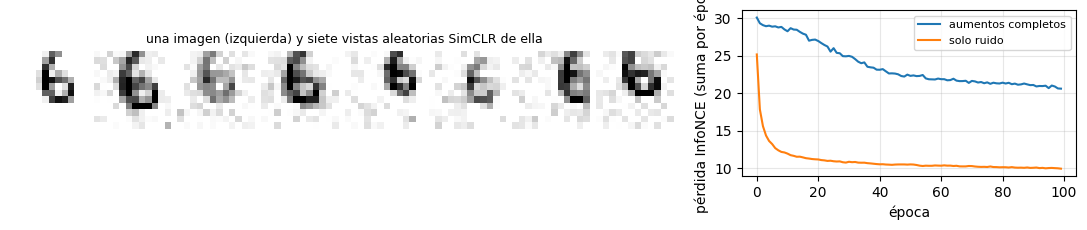

In [7]:
# los mismos dígitos pegados en una posición aleatoria dentro de un lienzo de 12x12
crng = np.random.RandomState(3)
XS = np.zeros((len(X), 12, 12), np.float32)
for i in range(len(X)):
    a, b = crng.randint(0, 5, 2)
    XS[i, a:a + 8, b:b + 8] = X[i].reshape(8, 8)
XS = XS.reshape(len(X), 144)
XStr, XSte = XS[itr], XS[ite]

def augment(x, geometric=True):
    # una vista aleatoria distinta de cada imagen del lote
    n = len(x); im = x.view(n, 1, 12, 12)
    if geometric:
        ang = (torch.rand(n) * 2 - 1) * math.radians(12)
        sc = torch.empty(n).uniform_(0.85, 1.15)
        tx = (torch.rand(n) * 2 - 1) * 0.35; ty = (torch.rand(n) * 2 - 1) * 0.35     # en unidades de medio lienzo (0.35 = unos 2 píxeles)
        th = torch.zeros(n, 2, 3)
        th[:, 0, 0] = torch.cos(ang) / sc; th[:, 0, 1] = -torch.sin(ang) / sc
        th[:, 1, 0] = torch.sin(ang) / sc; th[:, 1, 1] = torch.cos(ang) / sc
        th[:, 0, 2] = tx; th[:, 1, 2] = ty
        im = F.grid_sample(im, F.affine_grid(th, im.shape, align_corners=False), align_corners=False)
        im = im * torch.empty(n, 1, 1, 1).uniform_(0.6, 1.4)
    im = im + 0.1 * torch.randn_like(im)
    return im.clamp(0, 1).view(n, 144)

def info_nce(z1, z2, tau=0.2):
    # NT-Xent: cada una de las 2N vistas debe elegir a su pareja entre las otras 2N-1 vistas
    z = F.normalize(torch.cat([z1, z2]), dim=1); n = len(z1)
    s = z @ z.T / tau
    s.fill_diagonal_(-1e9)                                           # una vista no es candidata de sí misma
    target = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)])
    return F.cross_entropy(s, target)

def make_encoder():
    return nn.Sequential(nn.Linear(144, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU())

def train_simclr(geometric, epochs=100, seed=0, bs=256):
    torch.manual_seed(seed)
    enc = make_encoder(); head = nn.Linear(64, 32)
    opt = torch.optim.Adam(list(enc.parameters()) + list(head.parameters()), 2e-3)
    Xt = torch.tensor(XStr); losses = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xt)); tot = 0
        for i in range(0, len(Xt), bs):
            xb = Xt[perm[i:i + bs]]
            loss = info_nce(head(enc(augment(xb, geometric))), head(enc(augment(xb, geometric))))
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()
        losses.append(tot)
    return enc, losses

t = time.time()
enc_strong, loss_strong = train_simclr(True)
enc_weak, loss_weak = train_simclr(False)
print(f"SimCLR entrenado dos veces en {time.time() - t:.0f} s; transcurrido {time.time() - T0:.0f} s")

# qué hacen los aumentos y qué aprendió de ellos el codificador contrastivo
torch.manual_seed(4)
one = torch.tensor(XSte[:1]).repeat(7, 1)
views = torch.cat([torch.tensor(XSte[:1]), augment(one)]).numpy()
with torch.no_grad():
    za = F.normalize(enc_strong(augment(torch.tensor(XSte))), dim=1); zb = F.normalize(enc_strong(augment(torch.tensor(XSte))), dim=1)
    wa = F.normalize(enc_weak(augment(torch.tensor(XSte))), dim=1); wb = F.normalize(enc_weak(augment(torch.tensor(XSte))), dim=1)
    perm = torch.randperm(len(za))
    pos_s, neg_s = (za * zb).sum(1).mean().item(), (za * zb[perm]).sum(1).mean().item()
    pos_w, neg_w = (wa * wb).sum(1).mean().item(), (wa * wb[perm]).sum(1).mean().item()
print(f"similitud coseno de las representaciones de 64-d de dos vistas geométricas: misma imagen {pos_s:.2f} vs imágenes distintas {neg_s:.2f}  (codificador con aumentos completos)")
print(f"                                                                       misma imagen {pos_w:.2f} vs imágenes distintas {neg_w:.2f}  (codificador con aumento débil)")
fig, axs = plt.subplots(1, 2, figsize=(11, 2.4), gridspec_kw={"width_ratios": [2, 1]})
axs[0].imshow(montage(views, 8, side=12), cmap="gray", vmin=0, vmax=1); axs[0].axis("off"); axs[0].grid(False)
axs[0].set_title("una imagen (izquierda) y siete vistas aleatorias SimCLR de ella", fontsize=9)
axs[1].plot(loss_strong, label="aumentos completos"); axs[1].plot(loss_weak, label="solo ruido"); axs[1].set_xlabel("época"); axs[1].set_ylabel("pérdida InfoNCE (suma por época)"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

precisión de prueba (media de 3 sorteos aleatorios del conjunto etiquetado); columnas: número de etiquetas
método                             10     20     50    100    200    400   1200
píxeles crudos                  0.131  0.156  0.192  0.235  0.251  0.269  0.323
codificador sin entrenar        0.126  0.139  0.183  0.217  0.246  0.286  0.357
características del autoencoder  0.137  0.159  0.194  0.194  0.216  0.255  0.307
SimCLR, solo ruido              0.146  0.175  0.227  0.271  0.342  0.396  0.451
SimCLR, aumentos completos      0.276  0.360  0.546  0.652  0.769  0.806  0.851
supervisado desde cero          0.135  0.168  0.227  0.296  0.405  0.583  0.833
mayor desviación típica entre sorteos, cualquier celda: 0.062 | transcurrido 283 s


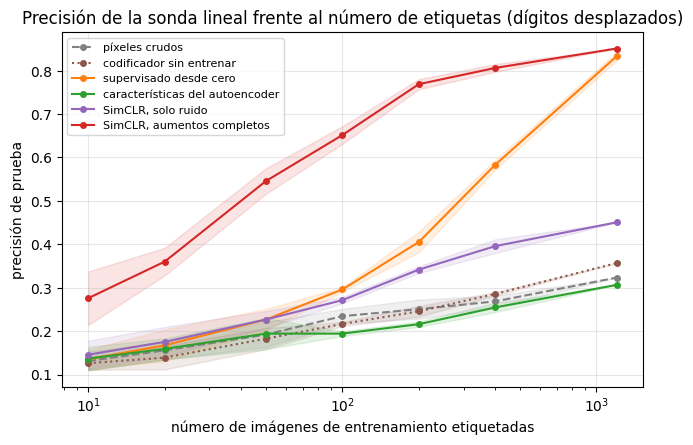

In [8]:
# los métodos de comparación
def sup_features_free(Xs_, ys_, seed):
    # supervisado desde cero: misma arquitectura + capa lineal, entrenada de extremo a extremo solo con n imágenes etiquetadas
    torch.manual_seed(seed)
    net = nn.Sequential(make_encoder(), nn.Linear(64, 10))
    opt = torch.optim.Adam(net.parameters(), 3e-3, weight_decay=1e-3)
    xt, yt = torch.tensor(Xs_), torch.tensor(ys_)
    for _ in range(200):
        loss = F.cross_entropy(net(xt), yt); opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return (net(torch.tensor(XSte)).argmax(1).numpy() == yte).mean()

# autoencoder sobre el lienzo de 12x12 (144 entradas), cuello de 32 números, sin etiquetas
torch.manual_seed(0)
ae_enc = make_mlp([144, 128, 32]); ae_dec = make_mlp([32, 128, 144], nn.Sigmoid())
opt = torch.optim.Adam(list(ae_enc.parameters()) + list(ae_dec.parameters()), 3e-3)
Xt = torch.tensor(XStr)
for ep in range(40):
    perm = torch.randperm(len(Xt))
    for i in range(0, len(Xt), 128):
        xb = Xt[perm[i:i + 128]]
        loss = F.mse_loss(ae_dec(ae_enc(xb)), xb); opt.zero_grad(); loss.backward(); opt.step()

torch.manual_seed(0)
enc_random = make_encoder()
with torch.no_grad():
    feats = {"píxeles crudos": XS,
             "codificador sin entrenar": enc_random(torch.tensor(XS)).numpy(),
             "características del autoencoder": ae_enc(torch.tensor(XS)).numpy(),
             "SimCLR, solo ruido": enc_weak(torch.tensor(XS)).numpy(),
             "SimCLR, aumentos completos": enc_strong(torch.tensor(XS)).numpy()}

def probe(Fm, sub):
    sc = StandardScaler().fit(Fm[itr][sub])
    clf = LogisticRegression(max_iter=500).fit(sc.transform(Fm[itr][sub]), ytr[sub])
    return clf.score(sc.transform(Fm[ite]), yte)

NS = [10, 20, 50, 100, 200, 400, 1200]
DRAWS = 3
acc = {k: np.zeros((len(NS), DRAWS)) for k in list(feats) + ["supervisado desde cero"]}
for a, n in enumerate(NS):
    for d in range(DRAWS):
        sub = np.random.RandomState(100 * d + n).choice(1200, n, replace=False)
        for k, Fm in feats.items():
            acc[k][a, d] = probe(Fm, sub)
        acc["supervisado desde cero"][a, d] = sup_features_free(XStr[sub], ytr[sub], d)

print("precisión de prueba (media de 3 sorteos aleatorios del conjunto etiquetado); columnas: número de etiquetas")
print(f"{'método':30}" + "".join(f"{n:>7}" for n in NS))
for k, v in acc.items():
    print(f"{k:30}" + "".join(f"{m:7.3f}" for m in v.mean(1)))
print("mayor desviación típica entre sorteos, cualquier celda:", round(max(v.std(1).max() for v in acc.values()), 3), "| transcurrido", round(time.time() - T0), "s")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
styles = {"píxeles crudos": ("gray", "--"), "codificador sin entrenar": ("C5", ":"), "supervisado desde cero": ("C1", "-"), "características del autoencoder": ("C2", "-"),
          "SimCLR, solo ruido": ("C4", "-"), "SimCLR, aumentos completos": ("C3", "-")}
for k, (c, ls) in styles.items():
    m, s = acc[k].mean(1), acc[k].std(1)
    ax.plot(NS, m, ls, color=c, marker="o", ms=4, label=k); ax.fill_between(NS, m - s, m + s, color=c, alpha=0.12)
ax.set_xscale("log"); ax.set_xlabel("número de imágenes de entrenamiento etiquetadas"); ax.set_ylabel("precisión de prueba"); ax.set_title("Precisión de la sonda lineal frente al número de etiquetas (dígitos desplazados)")
ax.legend(fontsize=8); plt.show()

**Lectura.** En dígitos desplazados, los píxeles crudos son un mal punto de partida (32 % con las 1.200 etiquetas, el mismo dígito enciende píxeles distintos en posiciones distintas) y la representación contrastiva con los aumentos completos va muy por delante con pocas etiquetas: 28 % con 10 etiquetas frente a 13 a 15 % de todos los demás métodos, 55 % con 50 etiquetas frente a 19 a 23 %, y 85 % con todas. Este es el argumento de la eficiencia de etiquetas del aprendizaje autosupervisado en una sola imagen: las 1.200 imágenes sin etiquetar valieron cientos de etiquetas. Los controles nos mantienen honestos. El codificador sin entrenar y las características del autoencoder no aportan nada sobre los píxeles crudos: un autoencoder es premiado por reconstruir **todos** los píxeles, incluido dónde está el dígito, así que su código conserva la molestia (la posición) que el clasificador necesita ignorar. SimCLR con aumento solo de ruido aprende algo (45 % frente a 32 % al final) pero muy lejos de la versión completa, lo que confirma que la ganancia viene de los aumentos, es decir, de lo que le dijimos a la red que no le importe; la similitud coseno de pares positivos (0,76 frente a 0,56 entre imágenes distintas, contra 0,55 y 0,45 del codificador de solo ruido) dice lo mismo. El supervisado desde cero queda cerca de los píxeles crudos hasta 50 etiquetas y solo alcanza a la curva contrastiva con todas las etiquetas (83 % frente a 85 %, dentro de la dispersión entre sorteos). Dos salvedades: primero, el tamaño de la brecha es una propiedad de estos datos y de esta elección de molestia (la posición); en los dígitos 8x8 centrados una sonda sobre píxeles crudos es difícil de superar (en una ejecución preliminar los tres estaban a pocos puntos, 96 a 97 % con todas las etiquetas). Segundo, 3 sorteos y una semilla de entrenamiento por método significa que las diferencias pequeñas entre las curvas inferiores son ruido (la mayor desviación típica entre sorteos es 0,06); la brecha con la curva superior para $n$ pequeño es mucho mayor. El artículo real de SimCLR informa del mismo efecto en ImageNet a una escala muy distinta (una red ResNet-50, 1,28 millones de imágenes, lotes de miles de imágenes, cientos de épocas en muchos aceleradores).

## 6. CLIP: alinear imágenes y texto

El aprendizaje contrastivo no exige que las dos vistas sean dos imágenes. **CLIP** (Radford et al., 2021) usa una **imagen** y su **descripción** como las dos vistas de la misma "cosa". Tiene dos codificadores, uno de imágenes $f_{\text{img}}$ y otro de texto $f_{\text{txt}}$, cada uno seguido de una proyección a un espacio compartido. Para un lote de $N$ pares forma la matriz $N \times N$ de similitudes coseno entre cada imagen y cada descripción, la multiplica por una escala aprendida $1/\tau$ y aplica la pérdida InfoNCE dos veces: cada imagen debe elegir su descripción entre las $N$ descripciones, y cada descripción debe elegir su imagen entre las $N$ imágenes (el promedio de las dos entropías cruzadas). La única diferencia con SimCLR es que las dos vistas vienen de modalidades distintas. El modelo original se entrenó con 400 millones de pares imagen-texto recogidos de la web.

Lo que se gana es un modelo al que se le puede **decir con palabras qué buscar**. Para clasificar una imagen en $K$ clases sin entrenamiento para esa tarea (**clasificación zero-shot**), se escribe una frase por clase ("una foto de un perro", "una foto de un gato"), se codifican con el codificador de texto y se elige la clase cuya frase se parece más a la imagen en el espacio compartido. La lista de clases es solo texto, así que puede cambiarse a voluntad.

**Parte 1: un CLIP en miniatura, desde cero.** Emparejamos cada imagen de dígito con una descripción aleatoria generada a partir de plantillas, por ejemplo "a handwritten seven", "the digit seven", "an odd digit", "a small digit" (0 a 4) o "this is an even and large number". Las descripciones se quedan en inglés dentro del código (son datos del modelo, no texto del cuaderno). El codificador de imágenes es una pequeña red densa. El codificador de texto es lo más simple que funciona: una incrustación aprendida para cada palabra, **promediada** sobre las palabras de la descripción (ignora el orden de las palabras, cosa que el CLIP real no hace; usa un Transformer), seguida de una red pequeña. Tras el entrenamiento probamos con imágenes no vistas y con **instrucciones que nunca se usaron en el entrenamiento**: la plantilla "this is the number seven" (todas sus palabras aparecen en el entrenamiento, pero nunca en esta combinación) e instrucciones que nombran solo una **propiedad** ("an even digit") en vez del dígito. Esa es la idea zero-shot en miniatura. Un detalle técnico: un lote puede contener dos imágenes del mismo dígito con la misma descripción, que la pérdida trata como falso negativo; con lote de 128 y diez clases ocurre a menudo, y limita la precisión final (el CLIP real tiene el mismo problema con los duplicados, a una tasa mucho menor gracias a sus lotes enormes y diversos).

CLIP diminuto entrenado en 700 pasos (299 s transcurridos). Precisión zero-shot en los 597 dígitos de prueba:
  10 clases, instrucción 'a handwritten <digit>' (vista en entrenamiento) : 0.985
  10 clases, instrucción 'this is the number <digit>' (nunca vista así)  : 0.980
  par contra impar, instrucciones 'an even digit' / 'an odd digit'      : 0.990  (azar 0.5)
  pequeño contra grande, instrucciones 'a small digit' / 'a large digit': 0.985  (azar 0.5)
  juez supervisado con etiquetas, como referencia                       : 0.975  (azar 0.1)


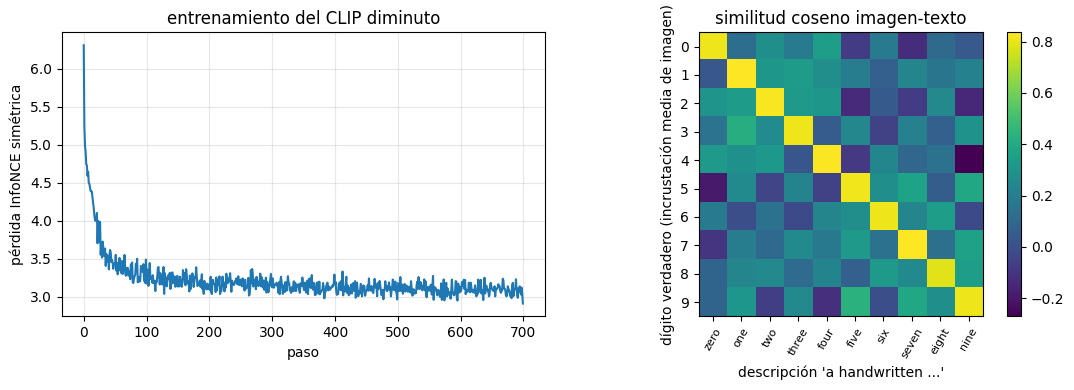

In [9]:
WORDS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
TEMPLATES = ["a handwritten {w}", "the digit {w}", "a picture of the number {w}", "{w}", "{w} is {p}", "an {p} digit",
             "a {s} digit", "this is an {p} and {s} number", "{w} is {s}"]
def parity(k): return "even" if k % 2 == 0 else "odd"
def size(k): return "small" if k < 5 else "large"

def caption(k, r):
    t = TEMPLATES[r.randint(len(TEMPLATES))]
    p = parity(k); s = size(k)
    t = t.replace("an {p}", "an " + p).replace("a {s}", "a " + s)           # artículo simple: "an even", "an odd"
    return t.format(w=WORDS[k], p=p, s=s)

vocab = sorted({w for k in range(10) for t in TEMPLATES for w in t.format(w=WORDS[k], p=parity(k), s=size(k)).split()}
               | {"this", "is", "the", "number", "an", "a", "even", "odd", "small", "large"})
w2i = {w: i for i, w in enumerate(vocab)}
MAXLEN = 8
def tokenize(caps):
    ids = torch.zeros(len(caps), MAXLEN, dtype=torch.long); mask = torch.zeros(len(caps), MAXLEN)
    for r, c in enumerate(caps):
        for j, w in enumerate(c.split()[:MAXLEN]):
            ids[r, j] = w2i[w]; mask[r, j] = 1
    return ids, mask

class TinyCLIP(nn.Module):
    def __init__(self, dim=32):
        super().__init__()
        self.img = make_mlp([64, 128, dim])
        self.emb = nn.Embedding(len(vocab), 32); self.txt = make_mlp([32, 64, dim])
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))      # la temperatura aprendida
    def encode_image(self, x): return F.normalize(self.img(x), dim=1)
    def encode_text(self, caps):
        ids, mask = tokenize(caps)
        e = (self.emb(ids) * mask[..., None]).sum(1) / mask.sum(1, keepdim=True)   # media de las incrustaciones de palabras
        return F.normalize(self.txt(e), dim=1)

torch.manual_seed(0); r = np.random.RandomState(0)
clip = TinyCLIP(); opt = torch.optim.Adam(clip.parameters(), 3e-3)
Xt = torch.tensor(Xtr); B = 128; hist = []
for step in range(700):
    idx = torch.randint(0, len(Xt), (B,))
    caps = [caption(int(ytr[i]), r) for i in idx]
    zi = clip.encode_image(Xt[idx]); zt = clip.encode_text(caps)
    logits = clip.logit_scale.exp().clamp(max=100) * zi @ zt.T
    tgt = torch.arange(B)
    loss = (F.cross_entropy(logits, tgt) + F.cross_entropy(logits.T, tgt)) / 2          # imagen->texto y texto->imagen
    opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())

with torch.no_grad():
    zi = clip.encode_image(torch.tensor(Xte))
    def zs(prompts): return (zi @ clip.encode_text(prompts).T)
    a_seen = (zs([f"a handwritten {w}" for w in WORDS]).argmax(1).numpy() == yte).mean()
    a_new = (zs([f"this is the number {w}" for w in WORDS]).argmax(1).numpy() == yte).mean()
    a_par = (zs(["an even digit", "an odd digit"]).argmax(1).numpy() == (yte % 2)).mean()
    a_siz = (zs(["a small digit", "a large digit"]).argmax(1).numpy() == (yte >= 5)).mean()
    sims = zs([f"a handwritten {w}" for w in WORDS]).numpy()
    mean_img = np.stack([zi[yte == k].mean(0).numpy() for k in range(10)])
    zt_all = clip.encode_text([f"a handwritten {w}" for w in WORDS]).numpy()
print(f"CLIP diminuto entrenado en 700 pasos ({time.time() - T0:.0f} s transcurridos). Precisión zero-shot en los 597 dígitos de prueba:")
print(f"  10 clases, instrucción 'a handwritten <digit>' (vista en entrenamiento) : {a_seen:.3f}")
print(f"  10 clases, instrucción 'this is the number <digit>' (nunca vista así)  : {a_new:.3f}")
print(f"  par contra impar, instrucciones 'an even digit' / 'an odd digit'      : {a_par:.3f}  (azar 0.5)")
print(f"  pequeño contra grande, instrucciones 'a small digit' / 'a large digit': {a_siz:.3f}  (azar 0.5)")
print(f"  juez supervisado con etiquetas, como referencia                       : {judge.score(Xte, yte):.3f}  (azar 0.1)")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(hist); axs[0].set_xlabel("paso"); axs[0].set_ylabel("pérdida InfoNCE simétrica"); axs[0].set_title("entrenamiento del CLIP diminuto")
im = axs[1].imshow(mean_img @ zt_all.T, cmap="viridis"); axs[1].set_xticks(range(10)); axs[1].set_xticklabels(WORDS, rotation=60, fontsize=8)
axs[1].set_yticks(range(10)); axs[1].set_ylabel("dígito verdadero (incrustación media de imagen)"); axs[1].set_xlabel("descripción 'a handwritten ...'"); axs[1].grid(False)
axs[1].set_title("similitud coseno imagen-texto"); plt.colorbar(im, ax=axs[1]); plt.tight_layout(); plt.show()

**Lectura.** La diagonal de la matriz de similitud es toda la idea: una imagen de un 3 se parece más a la descripción "three", habiéndolo aprendido solo a partir de pares. Las filas zero-shot muestran que el espacio compartido es más que una tabla de consulta. Una plantilla que nunca apareció en esta combinación sigue clasificando al 98 %, y una instrucción que nombra solo una propiedad ("an even digit") separa pares de impares al 99 %, porque las palabras "even" y "odd" se alinearon con las imágenes de esos dígitos a través de las descripciones que las mencionan, en el mismo espacio que los nombres de los dígitos. Cuidado con la comparación con el juez supervisado (97,5 %): nuestras descripciones contienen la palabra de la etiqueta, así que la descripción es tan informativa como una etiqueta; la diferencia es que la supervisión llega como texto y se puede consultar con frases nuevas. Los duplicados dentro del lote (mismo dígito, misma descripción) actúan como falsos negativos pero no impidieron el entrenamiento. Esto es un juguete: las descripciones salen de nueve plantillas y un vocabulario de 30 palabras. Lo importante del modelo real es que la misma maquinaria, entrenada con 400 millones de descripciones de la web, maneja texto abierto.

**Parte 2: un CLIP real preentrenado, en la CPU.** Entrenar un CLIP útil requiere cientos de días de acelerador, así que usamos el punto de control publicado **openai/clip-vit-base-patch32** ([ficha del modelo](https://huggingface.co/openai/clip-vit-base-patch32), [artículo](https://arxiv.org/abs/2103.00020)): un Vision Transformer con parches de 32 píxeles como codificador de imágenes y un Transformer como codificador de texto, unos 150 millones de parámetros en total. La ficha del modelo no declara una licencia propia; el repositorio de código de OpenAI [github.com/openai/CLIP](https://github.com/openai/CLIP) tiene **licencia MIT** (comprueba tú mismo las condiciones antes de cualquier uso comercial de los pesos). La ficha dice que el modelo es para investigación, que su rendimiento varía según la clase y la tarea, y que tiene sesgos documentados, así que no debe desplegarse sin estudiar la tarea. La primera llamada descarga unos 600 MB una vez en la caché de Hugging Face (`~/.cache/huggingface`) y necesita el paquete `transformers`; si falta la red o el paquete, la celda imprime el motivo y no hace nada.

Clasificamos unas pocas fotografías incluidas en las bibliotecas scikit-image (la astronauta Eileen Collins, fotografía de la NASA de dominio público; una taza de café; un gato, "chelsea", CC0; un lanzamiento de cohete, SpaceX Falcon 9, CC0; todas de los [datos de scikit-image](https://scikit-image.org/docs/stable/api/skimage.data.html), ver allí las notas de licencia) y scikit-learn (un templo chino y una flor, imágenes Creative Commons, ver [la página de conjuntos de datos de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_sample_images.html)) frente a una lista de frases candidatas que **escribimos en el momento y con las que el modelo nunca entrenó**: el clasificador zero-shot. Después lo ejecutamos sobre los dígitos 8x8 (ampliados a 224 píxeles) con las instrucciones "a photo of the number N", y lo comparamos con nuestro CLIP diminuto, que sí vio los dígitos en el entrenamiento.

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:  89%|████████▉ | 354/398 [00:00<00:00, 3487.98it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 3602.06it/s]

cargado openai/clip-vit-base-patch32 (151 M parámetros) en 7 s


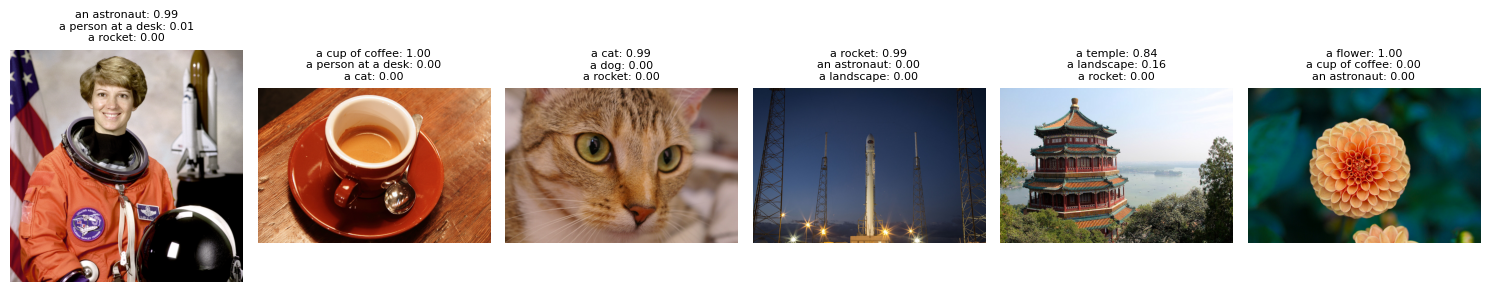

zero-shot, primera opción por imagen: {'astronaut': 'an astronaut', 'coffee': 'a cup of coffee', 'cat': 'a cat', 'rocket': 'a rocket', 'temple': 'a temple', 'flower': 'a flower'}


CLIP real, zero-shot en 150 dígitos de prueba (nunca entrenado en esta tarea): precisión 0.133   | CLIP diminuto (vio estos dígitos): 0.985   | regresión logística con 1.200 etiquetas: 0.975
transcurrido en esta celda 94 s; total 407 s


In [10]:
import os
try:
    from transformers import CLIPModel, CLIPProcessor
    from PIL import Image
    from skimage import data as skdata
    from sklearn.datasets import load_sample_images
    torch.set_num_threads(2)
    t = time.time()
    NAME = "openai/clip-vit-base-patch32"
    model = CLIPModel.from_pretrained(NAME).eval(); proc = CLIPProcessor.from_pretrained(NAME)
    print(f"cargado {NAME} ({sum(p.numel() for p in model.parameters()) / 1e6:.0f} M parámetros) en {time.time() - t:.0f} s")

    sk = load_sample_images()
    photos = {"astronaut": skdata.astronaut(), "coffee": skdata.coffee(), "cat": skdata.chelsea(), "rocket": skdata.rocket(),
              "temple": sk.images[0], "flower": sk.images[1]}
    labels = ["a cat", "a dog", "an astronaut", "a cup of coffee", "a rocket", "a temple", "a flower", "a car", "a landscape", "a person at a desk"]
    prompts = [f"a photo of {l}" for l in labels]
    with torch.no_grad():
        inp = proc(text=prompts, images=[Image.fromarray(p) for p in photos.values()], return_tensors="pt", padding=True)
        out = model(**inp)
        probs = out.logits_per_image.softmax(1).numpy()
    fig, axs = plt.subplots(1, len(photos), figsize=(15, 3.3))
    for ax, (name, im), p in zip(axs, photos.items(), probs):
        top = p.argsort()[::-1][:3]
        ax.imshow(im); ax.axis("off"); ax.grid(False)
        ax.set_title("\n".join(f"{labels[j]}: {p[j]:.2f}" for j in top), fontsize=8)
    plt.tight_layout(); plt.show()
    print("zero-shot, primera opción por imagen:", {n: labels[p.argmax()] for n, p in zip(photos, probs)})

    # el mismo modelo sobre los dígitos, ampliados de 8x8 a 224x224, tinta oscura sobre blanco
    sel = np.random.RandomState(0).choice(len(Xte), 150, replace=False)
    imgs = [Image.fromarray((255 * (1 - Xte[i].reshape(8, 8))).astype(np.uint8)).resize((224, 224), Image.NEAREST).convert("RGB") for i in sel]
    dprompts = [f"a photo of the number {k}" for k in range(10)]
    pred = []
    with torch.no_grad():
        for i in range(0, len(imgs), 25):
            o = model(**proc(text=dprompts, images=imgs[i:i + 25], return_tensors="pt", padding=True))
            pred.append(o.logits_per_image.argmax(1).numpy())
    pred = np.concatenate(pred)
    print(f"CLIP real, zero-shot en {len(sel)} dígitos de prueba (nunca entrenado en esta tarea): precisión {(pred == yte[sel]).mean():.3f}   | CLIP diminuto (vio estos dígitos): {a_seen:.3f}   | regresión logística con 1.200 etiquetas: {judge.score(Xte, yte):.3f}")
    print(f"transcurrido en esta celda {time.time() - t:.0f} s; total {time.time() - T0:.0f} s")
except Exception as e:
    print("Parte del CLIP real omitida:", type(e).__name__, str(e)[:200])
    print("Necesita `pip install transformers pillow` y acceso a la red una vez para descargar el punto de control (unos 600 MB).")

**Lectura.** En nuestra ejecución las seis fotografías se clasifican correctamente a partir de frases que inventamos hace un minuto, sin entrenamiento para esta tarea: ese es el significado práctico de zero-shot. Las probabilidades dependen de la lista de candidatas (es una softmax sobre nuestras diez frases, así que una foto cuya descripción verdadera no está entre las opciones se ve forzada hacia la errónea más cercana) y de la redacción de la instrucción, por lo que el artículo del CLIP real dedica una sección a la ingeniería de instrucciones. En los dígitos, una imagen de 8x8 ampliada a 224 píxeles está muy lejos de las fotografías de la web con las que se entrenó el modelo, la precisión zero-shot queda cerca del azar (13 % en nuestra ejecución, el azar es 10 %), muy por debajo de nuestro CLIP diminuto entrenado con estos mismos datos (98 %) y de un clasificador supervisado. Una muestra de 150 dígitos da un error típico de unos 3 puntos, así que el modelo real está, como mucho, ligeramente por encima del azar aquí. Es un resultado negativo que vale la pena conservar: el zero-shot funciona con lo que se parece a la distribución de entrenamiento, y un dígito 8x8 pixelado no se parece. El zero-shot cambia los últimos puntos de precisión en una tarea estrecha y bien definida por flexibilidad, y falla con imágenes especializadas o sintéticas como estas, donde el siguiente paso sería el ajuste fino o una sonda sobre sus características. Revisa siempre la ficha del modelo antes de usarlo con personas o en un producto: la ficha de CLIP enumera las limitaciones y sesgos conocidos.

## 7. Hacia dónde lleva esto: difusión y modelos generalistas

Cada idea de este cuaderno es una pieza de los modelos que verás a continuación.

* **De los autoencoders y VAEs a la difusión latente.** Los generadores de imágenes modernos no trabajan sobre píxeles. Un autoencoder (variacional y, en la práctica, entrenado también de forma adversaria) comprime cada imagen a una pequeña rejilla latente, y el modelo generativo trabaja dentro de ese espacio latente, mucho más barato. El decodificador del VAE de este cuaderno es la parte que convierte el latente final de vuelta en una imagen. Los mismos modelos toman además prestada la idea de eliminación de ruido de la sección 2: un **modelo de difusión** es un autoencoder con eliminación de ruido entrenado con muchos niveles de ruido y aplicado repetidamente. El módulo 05 de Neural Networks 1002 construye uno.
* **De las GANs a la difusión.** El juego antagónico dio imágenes nítidas y entrenamiento inestable; la difusión sustituyó el juego por una regresión estable que cubre todos los modos, al coste de muchos pasos de muestreo. Los discriminadores de las GAN sobreviven como pérdidas perceptuales y en los decodificadores de los autoencoders anteriores.
* **Del preentrenamiento contrastivo a la generación condicionada por texto.** El codificador de texto de un modelo tipo CLIP es la forma estándar de decirle a un generador qué dibujar: la instrucción se codifica en el espacio compartido (o en su secuencia de vectores de palabras) y la red de difusión se condiciona con ella mediante atención cruzada, algo que el módulo 05 de Neural Networks 1002 estudia con un punto de control real. La alineación contrastiva texto-imagen es también la forma en que las imágenes entran en los grandes modelos de lenguaje.
* **Del aprendizaje autosupervisado a los modelos generalistas.** La receta "predecir una parte de los datos a partir del resto, a escala, sin etiquetas" es la raíz común de los modelos de lenguaje, los modelos visión-lenguaje y los modelos generalistas del módulo 15 de Neural Networks 1002: la tarea pretexto cambia (palabra siguiente, parche enmascarado, descripción coincidente) pero la economía es la misma, los datos sin etiquetar pagan la representación y unas pocas etiquetas o una instrucción la especializan.

## 8. Ideas clave, ejercicios, referencias

**Ideas clave**

* Un cuello de botella obliga a un autoencoder a aprender estructura en vez de copiar, y el **error de reconstrucción** de un modelo entrenado con datos normales es una **puntuación de anomalía** ya hecha; un cuello demasiado ancho deja al modelo reconstruir también las anomalías, y la eliminación de ruido es la forma de mantener honesto a uno ancho.
* Un **VAE** añade un término KL a la pérdida de reconstrucción (la ELBO) y usa el **truco de reparametrización** para retropropagar a través del muestreo. El término KL hace el espacio latente suave y muestreable, y es justo lo que vuelve las muestras más **borrosas**: el peso $\beta$ cambia nitidez por un espacio latente bien organizado.
* Una **GAN** sustituye una pérdida fija por un crítico aprendido. Sus imágenes son más nítidas, pero el entrenamiento es un juego, no una optimización: las curvas de pérdida dicen poco, el equilibrio importa, y el **colapso de modos** (pocos grupos cubiertos) se mide con cobertura, tasa de acierto y diversidad, no con la pérdida. La pérdida hinge no rescató un juego desequilibrado en nuestra ejecución, y nuestra ejecución corta de Wasserstein falló; ambas necesitan cuidado y un presupuesto mayor.
* El **aprendizaje contrastivo** con una pérdida **InfoNCE** aprende representaciones a partir de datos sin etiquetar; **los aumentos definen lo que la representación ignora**. En nuestra curva de sonda lineal, las características de los aumentos adecuados valieron cientos de etiquetas, y la misma arquitectura entrenada solo con las etiquetas no fue mejor que los píxeles crudos con $n$ pequeño; el control con aumento solo de ruido no mostró ese beneficio.
* **CLIP** aplica la misma pérdida a pares imagen-descripción, y un espacio compartido de imágenes y texto permite la clasificación **zero-shot** con instrucciones escritas a voluntad. El punto de control real funciona con fotografías y es mucho más débil con dígitos sintéticos diminutos.
* Todos los números de aquí vienen de datos diminutos, una o pocas semillas y entrenamientos cortos: muestran mecanismos y la dirección de los efectos, no un rendimiento de producción.

**Ejercicios**

1. En la sección 2, retén la clase 1 (un dígito simple) en vez de la 5 y la 9. ¿El AUC de anomalía es mayor o menor, y por qué el error de reconstrucción de un trazo fino se comporta distinto? Añade $d = 64$ y $d = 128$ y observa dónde se rompe el autoencoder simple.
2. Sustituye el ruido del autoencoder con eliminación de ruido por **enmascaramiento** (pon a cero un cuarto aleatorio de los píxeles) y compara el AUC en $d = 32$. ¿Qué corrupción es mejor para detectar anomalías?
3. En la sección 3, entrena el VAE con $\beta = 0$ (un autoencoder simple con código aleatorio). ¿Qué ocurre con el término KL y con las muestras de la a priori? Después prueba el **recocido del KL**: aumenta $\beta$ linealmente de 0 a 1 durante las primeras 30 épocas.
4. Calcula para cada VAE las **dimensiones activas** del código de 8 dimensiones (aquellas cuya media posterior varía más de 0,1 en el conjunto de prueba). ¿Cuántas se usan? Es el "colapso posterior" en forma leve.
5. En la sección 4, ejecuta la GAN equilibrada sobre el anillo con 8 semillas en vez de 3 e informa de la distribución de modos cubiertos. Después cambia a 5 los pasos del discriminador por paso del generador. ¿Cuándo se estabiliza el juego y cuándo se atasca?
6. Ejecuta el crítico de Wasserstein de `train_toy` durante 4.000 pasos del generador. ¿Alcanza su tasa de acierto a la de la GAN simple? Dibuja la pérdida del crítico: ¿sigue la calidad de las muestras, como se afirma?
7. En la sección 5, cambia la temperatura $\tau$ a 0,05 y a 1,0, y el tamaño del lote a 64 y 1.200. ¿Qué configuración perjudica más con 20 etiquetas? ¿Por qué a los métodos contrastivos les gustan los lotes grandes (más negativos)?
8. Añade un aumento nuevo a SimCLR (por ejemplo el borrado aleatorio de un parche de 3x3) y uno que **contradiga** la tarea (por ejemplo girar hasta 180 grados: un 6 y un 9 ahora se parecen). Mide la sonda lineal con 50 etiquetas. ¿Perjudica un aumento equivocado?
9. En la sección 6, dale al CLIP diminuto una plantilla de descripción que sea incorrecta para el 10 % de las imágenes (un nombre de dígito al azar). ¿Qué tan robusta es la precisión zero-shot a descripciones ruidosas? (Las descripciones reales de la web también son ruidosas.)
10. Usa el CLIP real con tus propias fotografías y una lista de candidatas en la que falte la descripción correcta. ¿Qué responde el modelo y por qué la probabilidad sigue siendo alta?

**Referencias**

* Hinton, G. E. y Salakhutdinov, R. R. (2006). Reducing the dimensionality of data with neural networks. *Science* 313(5786), 504-507: https://doi.org/10.1126/science.1127647
* Vincent, P., Larochelle, H., Bengio, Y. y Manzagol, P.-A. (2008). Extracting and composing robust features with denoising autoencoders. *ICML*, 1096-1103: https://doi.org/10.1145/1390156.1390294
* Kingma, D. P. y Welling, M. (2014). Auto-encoding variational Bayes. *ICLR*. arXiv:1312.6114: https://arxiv.org/abs/1312.6114
* Higgins, I. et al. (2017). beta-VAE: learning basic visual concepts with a constrained variational framework. *ICLR*: https://openreview.net/forum?id=Sy2fzU9gl
* Goodfellow, I. et al. (2014). Generative adversarial nets. *NeurIPS*. arXiv:1406.2661: https://arxiv.org/abs/1406.2661
* Arjovsky, M., Chintala, S. y Bottou, L. (2017). Wasserstein GAN. arXiv:1701.07875: https://arxiv.org/abs/1701.07875
* Gulrajani, I., Ahmed, F., Arjovsky, M., Dumoulin, V. y Courville, A. (2017). Improved training of Wasserstein GANs. *NeurIPS*. arXiv:1704.00028: https://arxiv.org/abs/1704.00028
* Lim, J. H. y Ye, J. C. (2017). Geometric GAN (la pérdida hinge para GANs). arXiv:1705.02894: https://arxiv.org/abs/1705.02894
* van den Oord, A., Li, Y. y Vinyals, O. (2018). Representation learning with contrastive predictive coding (InfoNCE). arXiv:1807.03748: https://arxiv.org/abs/1807.03748
* Chen, T., Kornblith, S., Norouzi, M. y Hinton, G. (2020). A simple framework for contrastive learning of visual representations (SimCLR). *ICML*. arXiv:2002.05709: https://arxiv.org/abs/2002.05709
* Radford, A. et al. (2021). Learning transferable visual models from natural language supervision (CLIP). *ICML*. arXiv:2103.00020: https://arxiv.org/abs/2103.00020
* OpenAI (2021). Ficha del modelo CLIP ViT-B/32: https://huggingface.co/openai/clip-vit-base-patch32 ; código y licencia (MIT): https://github.com/openai/CLIP
* Alpaydin, E. y Kaynak, C. (1998). Optical recognition of handwritten digits. UCI Machine Learning Repository (CC BY 4.0): https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits
* Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *JMLR* 12, 2825-2830: https://jmlr.org/papers/v12/pedregosa11a.html
* van der Walt, S. et al. (2014). scikit-image: image processing in Python. *PeerJ* 2:e453: https://doi.org/10.7717/peerj.453